In [70]:
import matplotlib.pyplot as plt
import platform

# 그림 속 한글이 네모로 나오지 않게
fonts = {"Windows":"Malgun Gothic", "Darwin":"AppleGothic"}
name = fonts.get(platform.system(), "NanumGothic")
plt.rcParams["font.family"] = name
plt.rcParams["axes.unicode_minus"] = False

### **1단계: 읽고 날짜 세 칸을 날짜로**

In [71]:
import pandas as pd
df = pd.read_csv("sales_data.csv")

dates = ["order_date", "shipping_date", "delivery_date"]
for col in dates:
    df[col] = pd.to_datetime(df[col])
df.shape

(1030, 14)

### **2단계: 중복 행 제거**

In [72]:
before = len(df)
df = df.drop_duplicates()
print(before,"->", len(df))

1030 -> 1004


### **3단계: 수량 > 100인 줄의 수량을 금액/단가로 복원**

In [73]:
bad = df["quantity"] > 100
df.loc[bad, "quantity"] = (df.loc[bad, "total_sales"] / df.loc[bad, "unit_price"]).round().astype(int)
diff = (df["total_sales"] - df["quantity"] * df["unit_price"]).abs()
print("고친 줄:", bad.sum(), " 수량 최대:", df["quantity"].max(), " 총액 안 맞는 줄:", (diff > 1).sum())

고친 줄: 22  수량 최대: 99  총액 안 맞는 줄: 0


### **4단계 : date_error 추가, sales_clean.csv 저장**

In [74]:
df["date_error"] = df["delivery_date"] < df["shipping_date"]

print(df["date_error"].sum(), "건,",df.shape)

147 건, (1004, 15)


### **5단계 : 배송 기간 (도착일 - 배송일)은 보통 며칠인가**

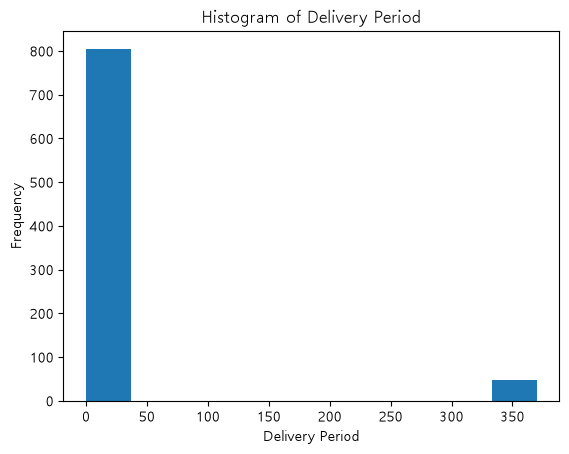

평균: 22.050469483568076
중앙값: 2.0


In [75]:
valid_df = df[df["date_error"] == False].copy()
valid_df["delivery_period"] = (valid_df["delivery_date"] - valid_df["shipping_date"]).dt.days

# 히스토그램 표현
plt.hist(valid_df["delivery_period"])
plt.xlabel("Delivery Period")
plt.ylabel("Frequency")
plt.title("Histogram of Delivery Period")
plt.show()

# 평균과 중앙값
print("평균:", valid_df["delivery_period"].mean())
print("중앙값:", valid_df["delivery_period"].median())

In [76]:
# 배송 기간이 300일을 넘는 레코드 출력
valid_df[valid_df["delivery_period"] > 300].head()

# shipping_date와 delivery_date의 연도가 약 1년 정도 차이 나는 것을 보아, 
# delivery_date의 연도가 잘못쓰였다고 판단

,order_date,shipping_date,delivery_date,region,category,product_id,quantity,unit_price,customer_id,customer_age,customer_gender,satisfaction,status,total_sales,date_error,delivery_period
11,2023-01-12,2023-01-15,2024-01-15,서울,가구,5557,59,169212.17,486,43.0,F,1.0,배송완료,9983518.03,False,365.0
20,2023-01-21,2023-01-23,2024-01-27,대구,가구,1270,39,105439.01,326,33.0,M,3.0,배송완료,4112121.39,False,369.0
29,2023-01-30,2023-02-03,2024-02-03,대구,전자제품,7771,94,446167.65,74,42.0,F,1.0,배송완료,41939759.10,False,365.0
41,2023-02-11,2023-02-14,2024-02-17,인천,전자제품,2380,55,290176.76,138,59.0,F,2.0,배송완료,15959721.80,False,368.0
68,2023-03-10,2023-03-14,2024-03-12,대구,의류,9463,6,73947.23,291,50.0,M,1.0,배송완료,443683.38,False,364.0


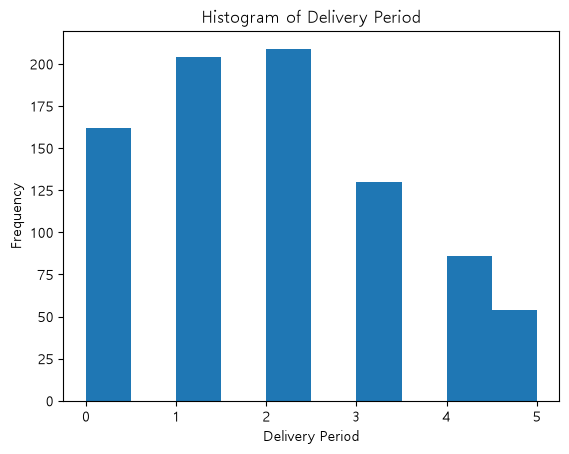

평균: 1.9242603550295858
중앙값: 2.0


In [77]:
# 기존 데이터에서 delivery_period가 300을 넘는 항목들의 delivery_date의 연도를 shipping_date의 연도로 수정
valid = df["date_error"] == False
df["delivery_period"] = (df.loc[valid, "delivery_date"] - df.loc[valid, "shipping_date"]).dt.days

mask = df["delivery_period"] > 300
df.loc[mask, "delivery_date"] = (df.loc[mask, "delivery_date"] - pd.DateOffset(years=1))

# 수정한 데이터를 기반으로 date_error 수정
df["date_error"] = df["delivery_date"] < df["shipping_date"]

# delivery_period 다시 구함
valid = df["date_error"] == False
df["delivery_period"] = (df.loc[valid, "delivery_date"] - df.loc[valid, "shipping_date"]).dt.days

# 수정한 데이터의 히스토그램 재출력
plt.hist(df["delivery_period"])
plt.xlabel("Delivery Period")
plt.ylabel("Frequency")
plt.title("Histogram of Delivery Period")
plt.show()

# 평균과 중앙값
print("평균:", df["delivery_period"].mean())
print("중앙값:", df["delivery_period"].median())

### 평균과 중앙값이 크게 다른 이유
히스토그램을 확인한 결과, 대부분의 배송 기간은 0~30일 사이에 집중되어 있지만 일부 데이터는 약 350일에 분포하고 있다. 이러한 극단적으로 긴 배송 기간이 평균을 크게 증가시킨 반면, 중앙값은 극단값의 영향을 상대적으로 적게 받기 때문에 평균과 중앙값 사이에 큰 차이가 발생하였다. 즉, 일부 장기 배송 데이터가 분포의 오른쪽 꼬리를 길게 만드는 오른쪽 편향 분포를 형성한 것으로 볼 수 있다.


### 오른쪽 끝 덩어리의 처리와 근거
`delivery_period`가 300일을 초과하는 데이터를 확인한 결과, `shipping_date`와 `delivery_date`의 연도가 약 1년 정도 차이 나는 것을 확인하였다. 이를 바탕으로 `delivery_date`의 연도가 잘못 입력되었을 가능성이 있다고 판단하였다.  

따라서 배송 기간이 300일을 초과하는 항목에 대해 `delivery_date`의 연도를 `shipping_date`의 연도에 맞추어 수정하였다. 이후 날짜 수정으로 인해 `date_error` 값이 변경되었을 가능성을 고려하여 오류 여부를 다시 확인하고, 추가적인 이상 데이터도 수정하였다.


### **6단계 : 만족도가 낮을수록 반품이 많은가**

In [78]:
# 반품 여부를 True / False로 저장
df["is_return"] = df["status"] == "반품"

# 만족도별 반품 비율 계산
return_ratio = df.groupby("satisfaction")["is_return"].mean() * 100

print(return_ratio)

satisfaction
1.0     7.589286
2.0    11.956522
3.0     7.812500
4.0     8.720930
5.0     6.930693
Name: is_return, dtype: float64


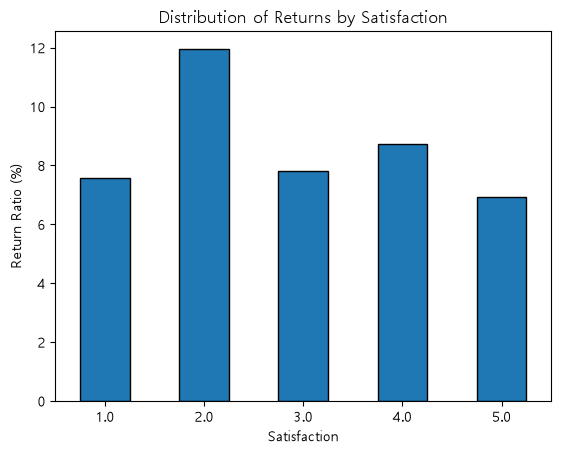

In [79]:
# 그래프 그리기
plt.figure()

return_ratio.plot(kind="bar", edgecolor="black")

plt.xlabel("Satisfaction")
plt.ylabel("Return Ratio (%)")
plt.title("Distribution of Returns by Satisfaction")
plt.xticks(rotation=0)

plt.show()

### 만족도가 낮을수록 반품이 많은가
"아니다", 만족도별 반품 비율을 비교한 결과, 만족도 2에서 약 12%로 가장 높은 반품 비율이 나타났으며, 만족도 5에서 약 6.9%로 가장 낮게 나타났다. 그러나 만족도가 낮아질수록 반품 비율이 일관되게 증가하는 경향은 확인할 수 없었다. 따라서 해당 데이터만으로는 만족도와 반품 비율 사이에 뚜렷한 관계가 있다고 판단하기 어렵다.

### **7단계 : 카테고리 매출 1위의 이유는 건수, 단가, 수량 중 무엇인가**

In [80]:
# 카테고리별 통계 계산
category_stats = df.groupby("category").agg(
    count=("product_id", "count"),          # 판매 기록 건수
    total_quantity=("quantity", "sum"),     # 총판매 수량
    avg_unit_price=("unit_price", "mean"),  # 평균 상품 단가
    avg_quantity=("quantity", "mean"),      # 평균 판매 수량
    total_sales=("total_sales", "sum")      # 총매출
)

print(category_stats)

          count  total_quantity  avg_unit_price  avg_quantity   total_sales
category                                                                   
가구          213           10872   257322.909061     51.042254  2.843337e+09
도서          204           10097   238500.636765     49.495098  2.453240e+09
식품          210            9936   255232.928143     47.314286  2.513274e+09
의류          170            8774   249447.162235     51.611765  2.181904e+09
전자제품        207            9928   249651.606135     47.961353  2.471628e+09


### 카테고리 매출 1위의 이유는 건수, 단가, 수량 중 무엇인가
카테고리별 매출을 비교한 결과, 가구가 약 28억 4,334만 원으로 매출 1위를 차지하였다. 가구는 판매 기록 건수가 213건으로 가장 많고, 평균 상품 단가도 약 257,323원으로 가장 높았다. 또한 총판매 수량 역시 10,872개로 가장 많았다. 따라서 가구 카테고리의 높은 매출은 판매 건수, 상품 단가, 총판매 수량이 모두 높은 데에서 비롯된 것으로 판단할 수 있다.